In [1]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.patches as patches
import pickle
import sys
sys.path.insert(0,'../src/')



from utils import *
from multiply_connected_pipe import *
from pipe_system import PipeSystem
from abstract_pipe import *
from curve import *

# Set up plotting parameters
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12


#### geometry creation

In [2]:
# Goal 1: Create T-shaped and L-shaped pipe junctions

print("Creating T-shaped pipe junctions...")

# Create T-shaped junction
# Parameters: length, radius, corner_size
t_pipe = TShaped(l=5.0, r=0.5, corner_size=1)
print(f"T-shaped pipe created with {t_pipe.n_lets} outlets")


# Build geometry for both pipes
print("\nBuilding pipe geometries...")
t_pipe.build_geometry(required_tol=1e-6)

print(f"T-pipe: {t_pipe.n_pts} boundary points")

Creating T-shaped pipe junctions...
1
1
T-shaped pipe created with 3 outlets

Building pipe geometries...
T-pipe: 2640 boundary points


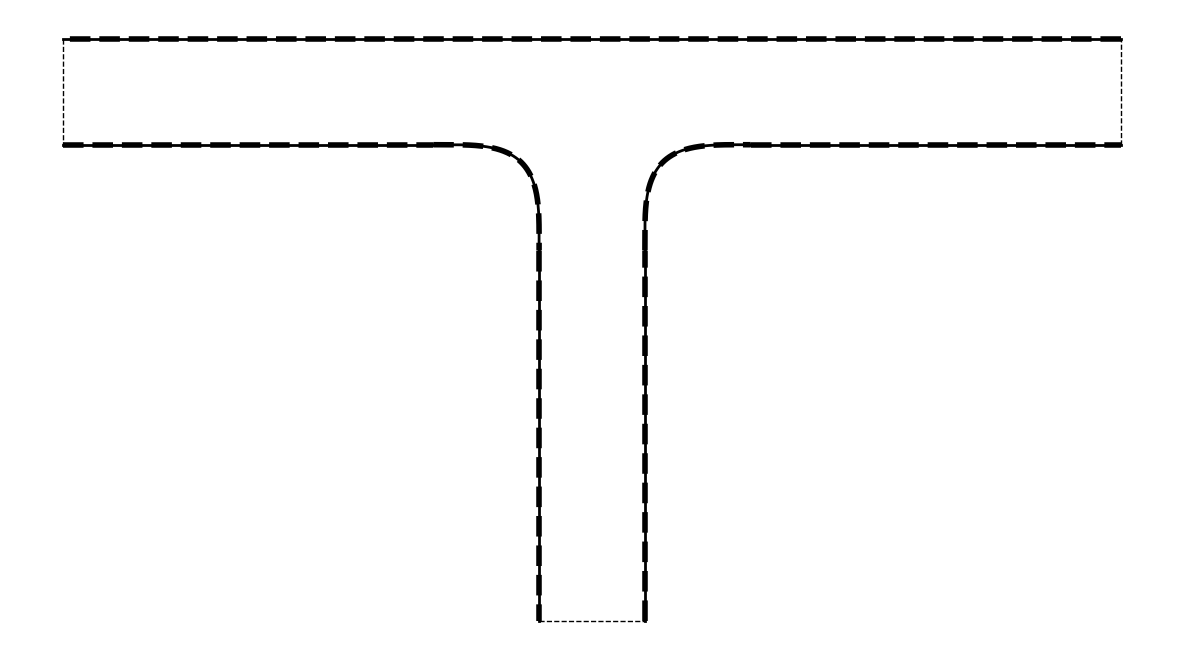

In [3]:
# Visualize the pipe geometries using the boundary plotting method
fig, ax = plt.subplots(tight_layout=True)

# Plot T-shaped pipe
ax.set_aspect('equal')
ax.axis('off')
t_pipe.exterior_boundary.plot_plyg_bdr(ax,color='k')

plt.show()

In [4]:
# Goal 2: Solve for characteristic flows with Poiseuille boundary conditions
print("Building complete solver for T-shaped pipes...")
# Build complete solvers - this includes geometry, matrices, and flow solutions
eps = 1e-5
t_pipe.build(required_tol=eps, fmm=True, density=20)

Building complete solver for T-shaped pipes...




/Users/haiy/git/fmm2d/python/fmm2dpy/fmm2d.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  out.pottarg,out.gradtarg,out.ier = lfmm.cfmm2d_t_d_g(eps,sources,dipstr,targets)


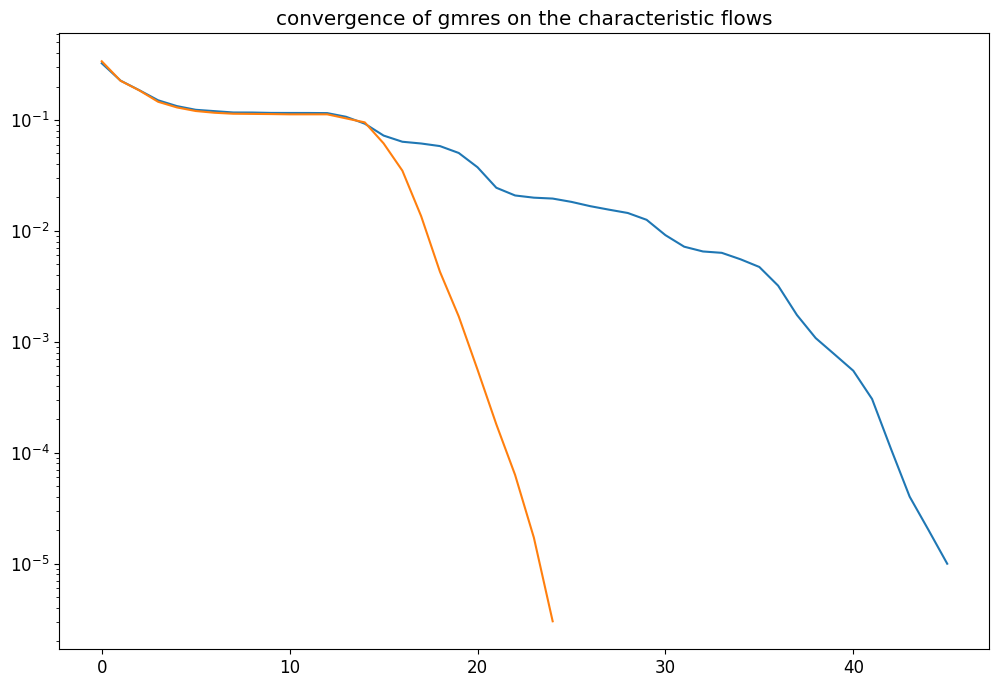

In [5]:
plt.semilogy(t_pipe.callbacks[0].residuals)
plt.semilogy(t_pipe.callbacks[1].residuals)
plt.title('convergence of gmres on the characteristic flows')
plt.show()

#### flows 

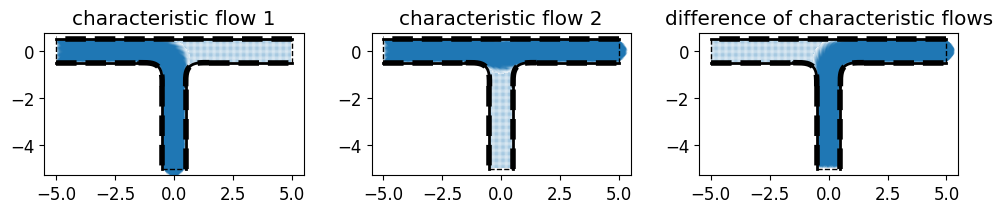

In [6]:
xs = t_pipe.xs
ys = t_pipe.ys

fig, axes = plt.subplots(1,3, figsize=(10,10),tight_layout=True)

axes[0].set_aspect('equal')
u0,v0,p0,o0 = t_pipe.fields_with_fluxes(np.array([1,0]),0,0)
t_pipe.exterior_boundary.plot_plyg_bdr(axes[0], color='k')
axes[0].quiver(xs, ys, u0, v0, scale=40, color='C0', width=0.003)
axes[0].set_title('characteristic flow 1')



axes[1].set_aspect('equal')
u1,v1,p1,o1 = t_pipe.fields_with_fluxes(np.array([0,1]),0,0)
t_pipe.exterior_boundary.plot_plyg_bdr(axes[1], color='k')
axes[1].quiver(xs, ys, u1, v1, scale=40, color='C0', width=0.003)
axes[1].set_title('characteristic flow 2')

axes[2].set_aspect('equal')
u2 = u1-u0
v2 = v1-v0
t_pipe.exterior_boundary.plot_plyg_bdr(axes[2], color='k')
axes[2].quiver(xs, ys, u2, v2, scale=40, color='C0', width=0.003, headwidth=10, headlength=10)
axes[2].set_title('difference of characteristic flows')

plt.show()

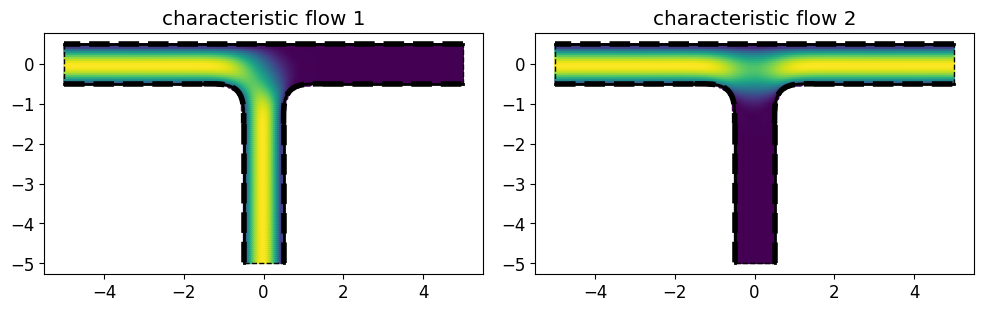

In [7]:
xs = t_pipe.xs
ys = t_pipe.ys

step = 1

fig, axes = plt.subplots(1,2, figsize=(10,10),tight_layout=True)

axes[0].set_aspect('equal')
u0,v0,p0,o0 = t_pipe.fields_with_fluxes(np.array([1,0]),0,0)
t_pipe.exterior_boundary.plot_plyg_bdr(axes[0], color='k')
axes[0].scatter(xs, ys, c=np.linalg.norm(np.array([u0,v0]),axis=0),s=10)
axes[0].set_title('characteristic flow 1')




axes[1].set_aspect('equal')
u1,v1,p1,o1 = t_pipe.fields_with_fluxes(np.array([0,1]),0,0)
t_pipe.exterior_boundary.plot_plyg_bdr(axes[1], color='k')
axes[1].scatter(xs, ys, c=np.linalg.norm(np.array([u1,v1]),axis=0),s=10)

axes[1].set_title('characteristic flow 2')

plt.show()

#### assembling the pipes

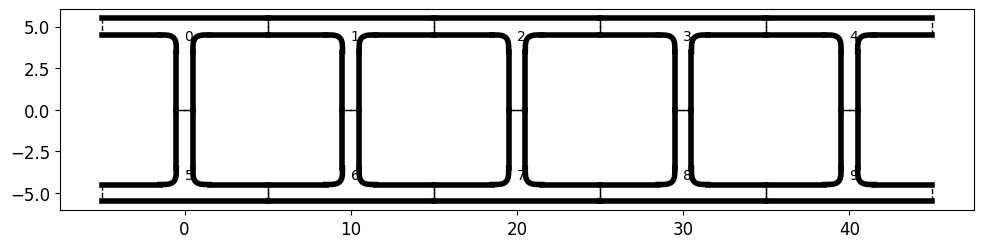

In [8]:
fig,ax = plt.subplots(figsize=(10,10),tight_layout=True)

pipes = [RealPipe(t_pipe,10*i,5,0) for i in range(5)] + [RealPipe(t_pipe,10*i,-5,np.pi) for i in range(5)]


for i,pipe in enumerate(pipes):
    pipe.plot_plyg_bdr(ax)
    x = np.mean(pipe.xs)
    y = np.mean(pipe.ys)
    ax.text(x,y,f'{i}',fontsize=10)

ax.set_aspect('equal')
# ax.axis('off')

plt.show()

#### re-development of the pipe-system solver 

fundamental variables: 
- the coefficients of characteristic flows of all pipes

fundamental constraints:
- pressure is path-irrelavent
- flux is preserved at each connection

boundary conditions (imposed by users):
- either pressures at each boundary 
- or flux at each boundary


nodes are the connection point or boundary let. 

In [28]:
flows = []
for ip,p in enumerate(pipes):
    for iflow in range(p.n_flows):
        flows.append((ip,iflow))
flows = list(enumerate(flows))
flows_idx2flow = dict(flows)
flow2flows_idx = {flow:idx for idx,flow in flows}

In [29]:
from itertools import product

In [30]:
_traverse = dict()

for ip,p in enumerate(pipes):
    for il,l in enumerate(p.lets):
        _traverse[(ip,il)] = (p,l)
        
_nodes = []


# internal nodes
for ((ip1,il1), (p1,l1)),((ip2,il2), (p2,l2)) in product(_traverse.items(),repeat=2):
    if ip1>=ip2: 
        continue
    if l1.almost_match(l2):
        # create an internal node
        _nodes.append({
            'node_type': 'internal',
            'let0': (ip1,il1),
            'let1': (ip2,il2),
            'pos': (l1.x,l1.y),
        })
        
# boundary nodes
for ((ip,il), (p,l)) in _traverse.items():
    pos = np.array([l.x,l.y])
    dist = np.min([np.linalg.norm(pos - n['pos'])  for n in _nodes])
    if dist < 1e-6:
        continue
    
    _nodes.append({
        'node_type': 'boundary',
        'let': (ip,il),
        'pos': (l.x,l.y),
    })

In [31]:
# creating the flux equations at each node
n_flows = len(flows)
flux_equations = []
for n in _nodes:
    if n['node_type'] != 'internal':
        continue
    
    let0 = n['let0']
    let1 = n['let1']
    
    equation = np.zeros(n_flows)
    p0,l0 = let0
    p1,l1 = let1
    
    for i, (ip,iflow) in flows:
        
        '''
        this flow is from the 0-th let to the i-flow-1 -th let in the pipe ip. 
        '''
        if ip == p0:
            if l0 == 0:
                equation[i] = -1 # flowing out of the node
            elif l0 == iflow+1:
                equation[i] = 1 # flowing into the node
            
        elif ip == p1:
            if l1 == 0:
                equation[i] = 1 # flowing into the node
            elif l1 == iflow+1:
                equation[i] = -1 # flowing out of the node
    
    flux_equations.append(equation)
flux_equations=np.array(flux_equations)


In [32]:
# create the graphs with all the edges
edges = []

def fn_lets(node):
    if node['node_type'] == 'internal':
        return [node['let0'],node['let1']]
    else:
        return [node['let']]
    
for ip,p in enumerate(pipes):
    for iflow in range(p.n_flows):
        
        start_let = (ip,0)    
        start_node_idx = [inode for inode,n in enumerate(_nodes) if start_let in fn_lets(n)][0]
        end_let = (ip,iflow+1)
        end_node_idx = [inode for inode,n in enumerate(_nodes) if end_let in fn_lets(n)][0]
        
        edges.append((start_node_idx,end_node_idx))


In [33]:
import networkx as nx

g = nx.Graph()
g.add_nodes_from(range(len(_nodes)))
g.add_edges_from(edges)

cycles = nx.cycle_basis(g)


In [35]:
# for each cycle, we will have a pressure drop equation

pressure_drop_equations = []



for cycle in cycles:
    
    equation = np.zeros(n_flows)
    
    for nidx0,nidx1 in zip(cycle,cycle[1:]+[cycle[0]]):
        
        # get the node
        n0 = _nodes[nidx0]
        n1 = _nodes[nidx1]
        
        
        # find the pipe
        p0 = set((ip for ip,il in fn_lets(n0)))
        p1 = set((ip for ip,il in fn_lets(n1)))
        
        p = p0.intersection(p1)
        
        assert len(p) == 1
        p = p.pop()
        
        # find the edge
        
        l0 = [il for ip,il in fn_lets(n0) if ip == p]
        l1 = [il for ip,il in fn_lets(n1) if ip == p]
        
        assert len(l0) == 1
        assert len(l1) == 1
        
        l0 = l0[0]
        l1 = l1[0]
        
        
        
        # sign of the edge
        sign = 1 if l0 == 0 else -1
        
        
        # which path
        ipath = max(l0,l1) - 1
        pressure_drop = sign * pipes[p].pressure_drops[:,ipath]
        
        # flow_index
        flow_index = [i for i,(pp,l) in flows if p==pp]
        
        equation[flow_index] = pressure_drop
        
    pressure_drop_equations.append(equation)
    
pressure_drop_equations = np.array(pressure_drop_equations)

In [36]:
n_flows

20

In [37]:
pressure_drop_equations.shape

(4, 20)

In [38]:
laws = np.vstack([pressure_drop_equations,flux_equations])

#### create the equation for the flux at all the boundary lets

In [39]:
# perscribe the flux at boundary let 

f_equations = []
boundary_lets = [n for n in _nodes if n['node_type'] == 'boundary']

for n in boundary_lets[:-1]:
    p,l = n['let']
    
    equation = np.zeros(n_flows)
    
    if l == 0:
        
        flow_idx = [i for i,(j,k) in flows if j == p]
        equation[flow_idx] = 1
        # flow in
        
    else:
        flow_idx = [i for i,(j,k) in flows if (j,k) == (p,l-1)]
        assert len(flow_idx) == 1
        flow_idx = flow_idx[0]
        equation[flow_idx] = -1
        # flow out
        
    f_equations.append(equation)
    
def flux_to_flow(flux):
    assert len(flux) == len(boundary_lets), f'flux should have {len(boundary_lets)} elements'
    assert np.isclose(np.sum(flux),0), f'net flux should be zero'
    
    A = np.vstack([f_equations,laws])
    b = np.concatenate([flux[:-1],np.zeros(laws.shape[0])])
    
    x = np.linalg.solve(A,b)
    
    return x
    

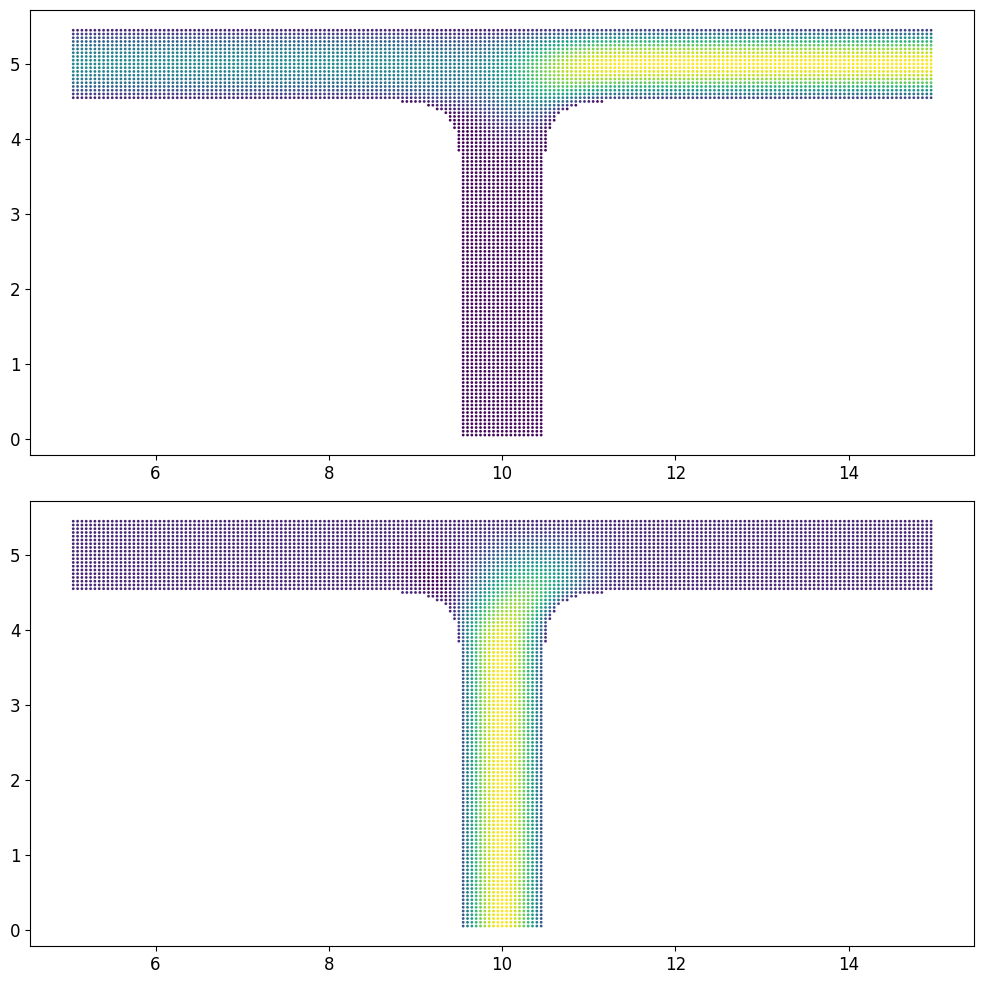

In [77]:

flow_coef = flux_to_flow([1,2,3,-6])

us = []
vs = []
xs = []
ys = []


for pidx,p in enumerate(pipes):    
    flow_idx = [i for i,(j,k) in flows if j==pidx] 
    coef = flow_coef[flow_idx]
    u,v,_,_ =  p.fields_with_fluxes(coef,0,0)
    
    if pidx == 1:
        us.append(u)
        vs.append(v)
        xs.append(p.xs)
        ys.append(p.ys)
    

fig,axes = plt.subplots(2,1,figsize=(10,10), tight_layout=True)

us = np.concatenate(us)
vs = np.concatenate(vs)
xs = np.concatenate(xs)
ys = np.concatenate(ys)


axes[0].scatter(xs,ys,c=us,s=1)
axes[1].scatter(xs,ys,c=vs,s=1)

plt.show()

In [64]:
u.shape, p.xs.shape

((5587,), (5587,))

In [53]:
flow_idx

[0, 1]

In [47]:
flows

[(0, (0, 0)),
 (1, (0, 1)),
 (2, (1, 0)),
 (3, (1, 1)),
 (4, (2, 0)),
 (5, (2, 1)),
 (6, (3, 0)),
 (7, (3, 1)),
 (8, (4, 0)),
 (9, (4, 1)),
 (10, (5, 0)),
 (11, (5, 1)),
 (12, (6, 0)),
 (13, (6, 1)),
 (14, (7, 0)),
 (15, (7, 1)),
 (16, (8, 0)),
 (17, (8, 1)),
 (18, (9, 0)),
 (19, (9, 1))]

In [27]:
[n for n in _nodes if n['node_type'] == 'boundary']

[{'node_type': 'boundary', 'let': (0, 0), 'pos': (-5.0, 5.0)},
 {'node_type': 'boundary', 'let': (4, 2), 'pos': (45.0, 5.0)},
 {'node_type': 'boundary', 'let': (5, 2), 'pos': (-5.0, -4.999999999999999)},
 {'node_type': 'boundary', 'let': (9, 0), 'pos': (45.0, -5.000000000000001)}]

#### create the equation for the pressure drops at all the boundary lets